# Bayesian Digital Twin (BDT) from scratch

This notebook builds the RADP **Bayesian Digital Twin** of a radio network from raw simulator output, then measures how good that twin is.

**The twin in one paragraph.** The BDT is one exact Gaussian process (GP) per cell. It learns the cell's received power `cell_rxpwr_dbm` at any location from three features:
- `log_distance`: distance from the site, on a log scale
- `relative_bearing`: angle away from the antenna's boresight
- `cell_el_deg`: the cell's electrical tilt

Features are min-max normalised. The kernel is a scaled RBF with ARD (one lengthscale per feature), and the hyperparameters are fitted by maximising the exact marginal log-likelihood with Adam. Because it is a GP, every prediction comes with its own uncertainty σ. New measurements can be folded in later with a cheap *fantasy update*, without retraining.

**What you will see**

| § | Question | Headline KPI / visual |
|---|---|---|
| 1–3 | What does the network look like, and what does tilt do to it? | topology, per-cell footprints, RSRP at 5 tilts |
| 4 | What does the twin see? | path-loss curve, antenna pattern |
| 5–6 | Training, and what the twin learned | loss curves, "watch it learn", ARD lengthscales |
| 7–9 | How accurate, and how honest, is it on a tilt it never saw? | MAE / RMSE / P95 / R², error and σ maps, calibration |
| 9b | How long should you train it? | accuracy vs calibration vs iterations |
| 10–11 | Can it answer what-if questions? | rx vs tilt with ±2σ bands, coverage and best server per tilt |
| 12–13 | Where does it break, and how much data does it need? | leave-one-tilt-out, learning curve |
| 14 | Can it adapt to a new configuration in under a second? | fantasy update vs full retrain |
| 15 | Ship it | pickle round-trip, final scorecard |

It runs end to end on a laptop CPU in 3–5 minutes. It reads the bundled `data/sim_data.zip` directly and needs only `radp`, PyTorch/GPyTorch and the scientific Python stack. No unzip step, no ffmpeg, no `radp_library`.

## 0 · Setup

In [ ]:
import sys
from pathlib import Path

sys.path.append(f"{Path().absolute().parent}")

In [ ]:
import copy
import logging
import pickle
import tempfile
import time
import warnings
import zipfile

import gpytorch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib import font_manager, patheffects
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap, TwoSlopeNorm
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy import stats

from radp.digital_twin.rf.bayesian.bayesian_engine import BayesianDigitalTwin, NormMethod
from radp.digital_twin.utils.gis_tools import GISTools

# the engine logs every optimiser iteration at INFO; keep the notebook readable
logging.getLogger("radp.digital_twin").setLevel(logging.WARNING)

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"torch {torch.__version__} | gpytorch {gpytorch.__version__} | pandas {pd.__version__}")

In [ ]:
SIM_ZIP = Path("data/sim_data.zip")
SIM_ROOT = "sim_data/3cell"  # the folder name is historical: the network has 5 cells
SIMS = ["sim_001", "sim_002", "sim_003", "sim_004", "sim_005"]
TEST_SIM = "sim_003"  # the tilt the twin never sees during training
TRAIN_SIMS = [sim for sim in SIMS if sim != TEST_SIM]

X_COLUMNS = ["log_distance", "relative_bearing", "cell_el_deg"]
Y_COLUMN = "cell_rxpwr_dbm"
P_TRAIN = 0.20  # fraction of each training simulation sampled per cell
MAXITER = 100  # Adam iterations; the engine stops early once the loss settles
COVERAGE_DBM = -105  # a location counts as covered when its RSRP is at least this
RSRP_RANGE = (-140, -70)  # shared colour range for every RSRP map
FOCUS_CELL = 1  # the cell used for the single-cell experiments

In [ ]:
# One palette for the whole notebook: categorical slots in fixed order for cells,
# one-hue ramps for magnitudes, and a blue <-> grey <-> red pair for signed error.
SURFACE, INK, INK_2, MUTED, GRID, AXIS, TILE = (
    "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f2f1ed",
)
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
ORDINAL_BLUES = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
RSRP_CMAP = LinearSegmentedColormap.from_list(
    "rsrp", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
SIGMA_CMAP = LinearSegmentedColormap.from_list(
    "sigma", ["#fde6da", "#f6b08f", "#eb6834", "#b8461b", "#7a2a0b"]
)
ERROR_CMAP = LinearSegmentedColormap.from_list(
    "error", ["#1c5cab", "#86b6ef", "#f0efec", "#f19a99", "#b8302f"]
)
for cmap in (RSRP_CMAP, SIGMA_CMAP, ERROR_CMAP):
    cmap.set_bad(SURFACE)

installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.family": "sans-serif",
        "font.sans-serif": [f for f in ["Helvetica Neue", "Helvetica", "Arial"] if f in installed_fonts]
        + ["DejaVu Sans"],
        "font.size": 9.5,
        "text.color": INK,
        "axes.titlesize": 10.5,
        "axes.titleweight": "semibold",
        "axes.titlelocation": "left",
        "axes.labelsize": 9,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "lines.linewidth": 1.6,
        "legend.frameon": False,
        "legend.fontsize": 8.5,
        "axes.prop_cycle": plt.cycler(color=SLOTS),
    }
)
HALO = [patheffects.withStroke(linewidth=3, foreground=SURFACE)]


def plain_log_axis(axis, ticks=None):
    """Log-scaled axis labelled with plain numbers instead of powers of ten."""
    if ticks is not None:
        axis.set_ticks(ticks)
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(NullFormatter())


def stat_tiles(tiles, title=None):
    """Render (value, label) pairs as a row of stat tiles."""
    fig, axes = plt.subplots(1, len(tiles), figsize=(2.45 * len(tiles), 1.25))
    for ax, (value, label) in zip(np.atleast_1d(axes), tiles):
        ax.set_axis_off()
        ax.add_patch(
            FancyBboxPatch(
                (0.03, 0.05), 0.94, 0.9, boxstyle="round,pad=0,rounding_size=0.08",
                transform=ax.transAxes, facecolor=TILE, edgecolor="none",
            )
        )
        ax.text(0.11, 0.6, value, transform=ax.transAxes, fontsize=17, fontweight="semibold", va="center")
        ax.text(0.11, 0.26, label, transform=ax.transAxes, fontsize=8.3, color=INK_2, va="center")
    fig.subplots_adjust(left=0.005, right=0.995, top=0.8 if title else 0.98, bottom=0.02, wspace=0.04)
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
    plt.show()


def kpis(y_true, y_pred, y_std=None):
    """Point-accuracy KPIs in dB, plus interval coverage when a predictive std is given."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    abs_err = np.abs(err)
    out = {
        "MAE (dB)": abs_err.mean(),
        "RMSE (dB)": np.sqrt(np.mean(err**2)),
        "P85 |err| (dB)": np.percentile(abs_err, 85),
        "P95 |err| (dB)": np.percentile(abs_err, 95),
        "bias (dB)": err.mean(),
        "R²": 1 - np.sum(err**2) / np.sum((y_true - y_true.mean()) ** 2),
    }
    if y_std is not None:
        z = abs_err / np.asarray(y_std, dtype=float)
        out["±1σ coverage"] = np.mean(z <= 1)
        out["±2σ coverage"] = np.mean(z <= 2)
    return out

## 1 · Load the raw simulator output

`sim_data.zip` holds five runs of the same network, one per electrical tilt (4°, 7°, 10°, 13° and 16°, applied to every cell). Each `full_data.csv` row is one **(location, cell)** pair: a pixel on the simulator's 1-arc-second grid and that cell's received power there. A location covered by several cells appears once per cell. The data is read straight from the archive.

In [ ]:
with zipfile.ZipFile(SIM_ZIP) as archive:
    site_config = pd.read_csv(archive.open(f"{SIM_ROOT}/{SIMS[0]}/site_config.csv"))
    raw = {sim: pd.read_csv(archive.open(f"{SIM_ROOT}/{sim}/full_data.csv")) for sim in SIMS}

TILT = {sim: int(df.cell_el_deg.iloc[0]) for sim, df in raw.items()}
CELLS = site_config.cell_id.tolist()
CELL_COLOR = dict(zip(CELLS, SLOTS))
CELL_INFO = site_config.set_index("cell_id")

# Snap every row onto the simulator's pixel grid. Coordinates carry ~1e-11 float noise,
# so integer grid indices (not raw floats) are what identify a location.
GRID_STEP = 1 / 3600
all_locs = pd.concat(raw.values())[["loc_x", "loc_y"]]
LON0, LAT0 = all_locs.loc_x.min(), all_locs.loc_y.min()
for df in raw.values():
    df["ix"] = np.rint((df.loc_x - LON0) / GRID_STEP).astype(int)
    df["iy"] = np.rint((df.loc_y - LAT0) / GRID_STEP).astype(int)
NX = max(df.ix.max() for df in raw.values()) + 1
NY = max(df.iy.max() for df in raw.values()) + 1
EXTENT = (LON0 - GRID_STEP / 2, LON0 + (NX - 0.5) * GRID_STEP, LAT0 - GRID_STEP / 2, LAT0 + (NY - 0.5) * GRID_STEP)
ASPECT = 1 / np.cos(np.deg2rad(LAT0 + NY * GRID_STEP / 2))  # metres-true map proportions

assert all(not df.duplicated(["ix", "iy", "cell_id"]).any() for df in raw.values())
print("tilt per simulation:", {sim: f"{tilt}°" for sim, tilt in TILT.items()})
display(site_config.drop(columns="cell_el_deg"))  # tilt is the one thing that changes per simulation

In [ ]:
n_sites = site_config[["cell_lat", "cell_lon"]].drop_duplicates().shape[0]
n_locations = raw[SIMS[0]][["ix", "iy"]].drop_duplicates().shape[0]
rx = pd.concat(raw.values())[Y_COLUMN]
stat_tiles(
    [
        (f"{len(SIMS)}", f"simulations · tilt {min(TILT.values())}–{max(TILT.values())}°"),
        (f"{len(CELLS)}", f"cells on {n_sites} sites"),
        (f"{len(raw[SIMS[0]]):,}", "(location, cell) rows per run"),
        (f"{n_locations:,}", "grid locations (~30 m pixels)"),
        (f"{rx.min():.0f} to {rx.max():.0f}", "received power range (dBm)"),
    ],
    title="Dataset at a glance",
)

## 2 · Topology and per-cell footprints

Each cell is trained as its own twin, on the locations it reaches. The left map shows where the sites point and how much the footprints overlap. Overlapping areas are where the strongest-cell (best-server) decision is made, so that decision is checked in §11. The small multiples show each cell's received power at the held-out 10° tilt: the footprint is an 800 m disc shaped by the antenna's horizontal pattern.

In [ ]:
def raster(ix, iy, values):
    grid = np.full((NY, NX), np.nan)
    grid[np.asarray(iy), np.asarray(ix)] = np.asarray(values, dtype=float)
    return grid


LABEL_NUDGE = {1: (0, -14), 4: (0, 14)}  # cells 1 and 4 point at each other; stack their labels


def draw_sites(ax, cells=None, arrows=False, labels=False, arrow_m=230):
    sites = site_config if cells is None else site_config[site_config.cell_id.isin(cells)]
    ax.scatter(sites.cell_lon, sites.cell_lat, marker="^", s=34, color=INK,
               edgecolor=SURFACE, linewidth=1.2, zorder=4)
    if not arrows:
        return
    for cell in sites.itertuples():
        dlat = arrow_m / 111_320 * np.cos(np.deg2rad(cell.cell_az_deg))
        dlon = arrow_m / (111_320 * np.cos(np.deg2rad(cell.cell_lat))) * np.sin(np.deg2rad(cell.cell_az_deg))
        tip = (cell.cell_lon + dlon, cell.cell_lat + dlat)
        ax.annotate("", xy=tip, xytext=(cell.cell_lon, cell.cell_lat),
                    arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.3, mutation_scale=9), zorder=4)
        if labels:
            ax.annotate(f"Cell {cell.cell_id}\n{cell.cell_az_deg}°", tip,
                        xytext=(16 * np.sin(np.deg2rad(cell.cell_az_deg)) + LABEL_NUDGE.get(cell.cell_id, (0, 0))[0],
                                16 * np.cos(np.deg2rad(cell.cell_az_deg)) + LABEL_NUDGE.get(cell.cell_id, (0, 0))[1]),
                        textcoords="offset points", ha="center", va="center",
                        fontsize=8, fontweight="semibold", path_effects=HALO, zorder=5)


def draw_map(ax, ix, iy, values, cmap=RSRP_CMAP, vmin=None, vmax=None, norm=None, title=None, cells=None):
    im = ax.imshow(raster(ix, iy, values), origin="lower", extent=EXTENT, cmap=cmap,
                   vmin=None if norm else vmin, vmax=None if norm else vmax, norm=norm, interpolation="nearest")
    ax.set_aspect(ASPECT)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    draw_sites(ax, cells=cells, arrows=cells is not None)
    if title:
        ax.set_title(title, fontsize=9.5)
    return im


def zoom_to(ax, rows, pad_px=3):
    """Crop a map to the pixels covered by `rows` (e.g. one cell's footprint)."""
    ax.set_xlim(LON0 + (rows.ix.min() - pad_px) * GRID_STEP, LON0 + (rows.ix.max() + pad_px) * GRID_STEP)
    ax.set_ylim(LAT0 + (rows.iy.min() - pad_px) * GRID_STEP, LAT0 + (rows.iy.max() + pad_px) * GRID_STEP)


def colorbar(fig, im, ax, label, **kwargs):
    cb = fig.colorbar(im, ax=ax, label=label, **kwargs)
    cb.outline.set_visible(False)
    cb.ax.tick_params(color=AXIS, labelsize=8)
    return cb


overlap = raw[TEST_SIM].groupby(["ix", "iy"]).size().reset_index(name="n_cells")
fig, ax = plt.subplots(figsize=(6.4, 4.8), layout="constrained")
overlap_cmap = ListedColormap(ORDINAL_BLUES)
overlap_cmap.set_bad(SURFACE)
im = draw_map(ax, overlap.ix, overlap.iy, overlap.n_cells, cmap=overlap_cmap,
              norm=BoundaryNorm(np.arange(0.5, 6), overlap_cmap.N))
draw_sites(ax, cells=CELLS, arrows=True, labels=True)
ax.set_title("Network topology · how many cells reach each location")
cb = colorbar(fig, im, ax, "cells reaching the location", ticks=range(1, 6), shrink=0.75)
plt.show()

shares = overlap.n_cells.value_counts(normalize=True).sort_index()
print("share of locations reached by k cells:", {k: f"{v:.0%}" for k, v in shares.items()})

In [ ]:
test_raw = raw[TEST_SIM]
fig, axes = plt.subplots(1, len(CELLS), figsize=(15, 3.6), layout="constrained")
for ax, cell_id in zip(axes, CELLS):
    rows = test_raw[test_raw.cell_id == cell_id]
    im = draw_map(ax, rows.ix, rows.iy, rows[Y_COLUMN], vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1],
                  title=f"Cell {cell_id} · azimuth {CELL_INFO.loc[cell_id, 'cell_az_deg']}°", cells=[cell_id])
    zoom_to(ax, rows)
colorbar(fig, im, axes, "received power (dBm)", shrink=0.85, pad=0.01)
fig.suptitle(f"Per-cell footprints at {TILT[TEST_SIM]}° tilt: what each twin has to learn",
             x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
plt.show()

## 3 · Ground truth: what tilt does to the network

Network RSRP is the strongest cell's power at each location. Down-tilting the antennas pulls energy toward the sites: coverage at the cell edge collapses while power near the sites barely moves. This is the trade-off a coverage and capacity optimiser (CCO) tunes, and the twin has to reproduce it.

In [ ]:
def network_view(rows, value_col, extra=()):
    """Strongest cell per grid location: its value and its id (the best server)."""
    best = rows.loc[rows.groupby(["ix", "iy"])[value_col].idxmax()]
    return best[["ix", "iy", "cell_id", value_col, *extra]].reset_index(drop=True)


fig, axes = plt.subplots(1, len(SIMS), figsize=(15, 3.6), layout="constrained")
true_coverage = {}
for ax, sim in zip(axes, SIMS):
    net = network_view(raw[sim], Y_COLUMN)
    true_coverage[sim] = (net[Y_COLUMN] >= COVERAGE_DBM).mean()
    im = draw_map(ax, net.ix, net.iy, net[Y_COLUMN], vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1],
                  title=f"{TILT[sim]}° tilt · {true_coverage[sim]:.0%} ≥ {COVERAGE_DBM} dBm"
                  + ("  (held out)" if sim == TEST_SIM else ""))
colorbar(fig, im, axes, "network RSRP (dBm)", shrink=0.85, pad=0.01)
fig.suptitle("Ground-truth network RSRP across the tilt sweep", x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
plt.show()

## 4 · Feature engineering: what the twin actually sees

The GP never sees latitude and longitude. Each (location, cell) row is described **relative to the cell**: the log of the distance to the site and the bearing measured from the antenna's boresight. Tilt is the third input. The vectorised `GISTools` helpers are used, and checked here against the scalar versions that `BayesianDigitalTwin.create_prediction_frames` uses at inference time, so training and serving features agree.

In [ ]:
def engineer_features(df):
    """Add the BDT inputs (log distance, relative bearing) to every (location, cell) row."""
    out = df.copy()
    for cell_id, rows in out.groupby("cell_id"):
        cell = CELL_INFO.loc[cell_id]
        out.loc[rows.index, "log_distance"] = GISTools.get_log_distance_vec(
            cell.cell_lat, cell.cell_lon, rows.loc_y.values, rows.loc_x.values
        )
        out.loc[rows.index, "relative_bearing"] = GISTools.get_relative_bearing_vec(
            cell.cell_az_deg, cell.cell_lat, cell.cell_lon, rows.loc_y.values, rows.loc_x.values
        )
    return out


data = {sim: engineer_features(df) for sim, df in raw.items()}

# parity with the scalar helpers used at inference time
for row in data[TEST_SIM].sample(50, random_state=SEED).itertuples():
    cell = CELL_INFO.loc[row.cell_id]
    assert np.isclose(row.log_distance, GISTools.get_log_distance(cell.cell_lat, cell.cell_lon, row.loc_y, row.loc_x))
    assert np.isclose(row.relative_bearing, GISTools.get_relative_bearing(cell.cell_az_deg, cell.cell_lat, cell.cell_lon, row.loc_y, row.loc_x))
print("vectorised features match the scalar helpers ✓")
data[TEST_SIM][["loc_x", "loc_y", "cell_id", *X_COLUMNS, Y_COLUMN]].describe().round(2)

In [ ]:
fig = plt.figure(figsize=(13, 4.6), layout="constrained")
ax_pl = fig.add_subplot(1, 2, 1)
ax_ap = fig.add_subplot(1, 2, 2, projection="polar")

dist_bins = np.geomspace(20, 800, 26)
for sim, color in zip(SIMS, ORDINAL_BLUES):
    rows = data[sim][data[sim].cell_id == FOCUS_CELL]
    off_boresight = np.minimum(rows.relative_bearing, 360 - rows.relative_bearing)
    rows = rows[off_boresight <= 30]
    dist_m = np.expm1(rows.log_distance)
    if sim == TEST_SIM:
        ax_pl.scatter(dist_m, rows[Y_COLUMN], s=3, color=AXIS, alpha=0.5, linewidth=0, zorder=1, label="_nolegend_")
    med = rows.groupby(pd.cut(dist_m, dist_bins), observed=True)[Y_COLUMN].median()
    centres = np.sqrt([b.left * b.right for b in med.index])
    ax_pl.plot(centres, med.values, color=color, lw=1.8, label=f"{TILT[sim]}°")
ax_pl.set_xscale("log")
plain_log_axis(ax_pl.xaxis, [25, 50, 100, 200, 400, 800])
ax_pl.set_xlabel("distance from site (m, log scale) · grey dots = individual 10° rows")
ax_pl.set_ylabel("received power (dBm)")
ax_pl.set_title(f"Path loss near boresight (±30°), cell {FOCUS_CELL} · median per distance bin")
ax_pl.legend(title="tilt", ncol=5, loc="lower left")

theta_bins = np.arange(0, 361, 6)
for sim, color in zip(SIMS, ORDINAL_BLUES):
    rows = data[sim][data[sim].cell_id == FOCUS_CELL]
    band = rows[np.expm1(rows.log_distance).between(300, 600)]
    pattern = band.groupby(pd.cut(band.relative_bearing, theta_bins), observed=True)[Y_COLUMN].mean()
    theta = np.deg2rad([b.mid for b in pattern.index])
    ax_ap.plot(np.append(theta, theta[0]), np.append(pattern.values, pattern.values[0]), color=color, lw=1.6)
ax_ap.set_theta_zero_location("N")
ax_ap.set_theta_direction(-1)
ax_ap.set_ylim(-140, -80)
ax_ap.set_yticks([-130, -110, -90])
ax_ap.set_yticklabels(["-130", "-110", "-90 dBm"], fontsize=7.5, color=INK_2)
ax_ap.tick_params(axis="x", labelsize=8)
ax_ap.set_title(f"Antenna pattern: mean rx vs bearing from boresight\n(300–600 m, cell {FOCUS_CELL}, colours = tilt as left)", pad=14)
plt.show()

**What to notice.**
- **Path loss.** Beyond about 150 m, received power falls almost linearly in log distance. That is the textbook path-loss law, and the reason the feature is `log_distance` rather than metres.
- **Tilt rotates the curve.** More tilt puts more power close to the mast, where the main beam now lands, and less at the cell edge. That is the coverage trade-off a CCO tunes.
- **Antenna pattern.** The front-to-back ratio is roughly 25–30 dB, so the twin has to resolve bearing at a much finer scale than tilt. §6 shows it learns exactly that.

## 5 · Train the twin

**Protocol.** For every cell, the twin is trained on a random 20% of that cell's rows from the four runs at **4°, 7°, 13° and 16°**, which stands in for drive-test or MDT measurements. It is evaluated on **every** row of the **10° run, which it never sees**.

Two things this does and does not test:
- **The tilt is held out; the space is not.** Test locations were measured at other tilts. That is the real use case: you have measured your network under its current configuration and want to predict a configuration you have not deployed.
- **Min-max normalisation needs at least two distinct values of every feature.** A twin trained on a single tilt gets `0/0 = NaN` tilt features unless you pass explicit `x_min`/`x_max`.

In [ ]:
train_df = pd.concat(
    [data[sim].groupby("cell_id", group_keys=False).sample(frac=P_TRAIN, random_state=SEED) for sim in TRAIN_SIMS],
    ignore_index=True,
)
test_df = data[TEST_SIM].reset_index(drop=True)

split = pd.DataFrame(
    {
        "train rows": train_df.groupby("cell_id").size(),
        "train tilts": train_df.groupby("cell_id").cell_el_deg.unique().map(lambda t: ", ".join(f"{v:g}°" for v in sorted(t))),
        "test rows": test_df.groupby("cell_id").size(),
        "test tilt": f"{TILT[TEST_SIM]}°",
    }
)
split.index.name = "cell"
split

In [41]:
def make_twin(rows):
    return BayesianDigitalTwin(
        data_in=[rows], x_columns=X_COLUMNS, y_columns=[Y_COLUMN], norm_method=NormMethod.MINMAX
    )


def fit(twin, maxiter=MAXITER):
    """Train in place; returns the loss trace (early-stopping padding removed) and wall time."""
    start = time.perf_counter()
    loss = twin.train_distributed_gpmodel(maxiter=maxiter)
    return loss[loss != 0], time.perf_counter() - start


def predict(twin, rows):
    """Posterior mean and std (dB) for one cell's rows. The engine mutates its input, so pass a copy."""
    mean, std = twin.predict_distributed_gpmodel(prediction_dfs=[rows.copy()])
    return mean[0], std[0]


twins, losses, train_secs = {}, {}, {}
for cell_id, rows in train_df.groupby("cell_id"):
    twins[cell_id] = make_twin(rows)
    losses[cell_id], train_secs[cell_id] = fit(twins[cell_id])
    print(f"cell {cell_id}: {len(rows):,} rows · {len(losses[cell_id])} iterations · {train_secs[cell_id]:.1f} s")
print(f"total training time: {sum(train_secs.values()):.1f} s")

cell 1: 2,492 rows · 100 iterations · 12.5 s
cell 2: 2,492 rows · 100 iterations · 9.5 s
cell 3: 2,488 rows · 100 iterations · 8.3 s
cell 4: 2,484 rows · 100 iterations · 7.2 s
cell 5: 2,488 rows · 100 iterations · 7.7 s
total training time: 45.2 s


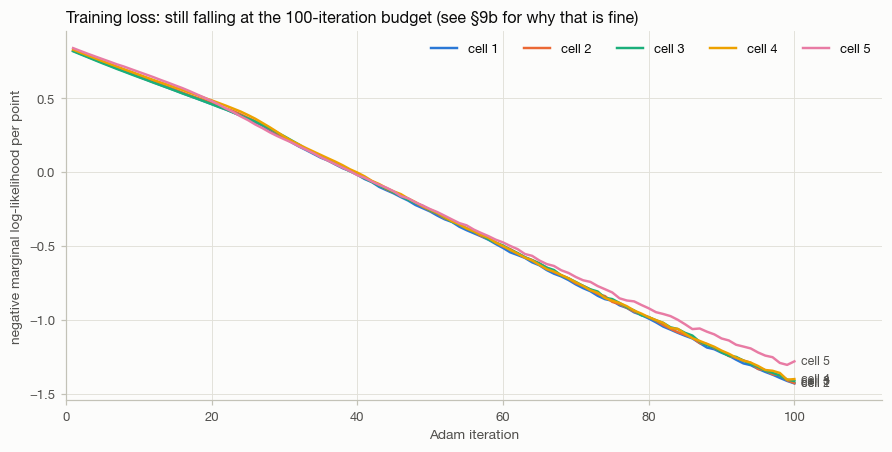

In [42]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for cell_id, loss in losses.items():
    ax.plot(np.arange(1, len(loss) + 1), loss, color=CELL_COLOR[cell_id], label=f"cell {cell_id}")
    ax.annotate(f"cell {cell_id}", (len(loss), loss[-1]), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK_2)
ax.set_xlabel("Adam iteration")
ax.set_ylabel("negative marginal log-likelihood per point")
ax.set_title(f"Training loss: still falling at the {MAXITER}-iteration budget (see §9b for why that is fine)")
ax.set_xlim(0, MAXITER + 12)
ax.legend(ncol=5, loc="upper right")
plt.show()

### Watch it learn

The coverage notebook animated predictions across training settings, which needs ffmpeg. The static version below shows the same thing: one cell's twin predicting the held-out 10° footprint after 0, 5, 20 and 100 optimiser steps. The top row is the prediction and the bottom row its error. At step 0 the hyperparameters are GPyTorch's defaults. The lengthscales are far too long to resolve the antenna lobe, so the prediction is a blur and the error map lights up along the sector edges. As the bearing lengthscale shrinks, the lobe sharpens and the error fades to grey.

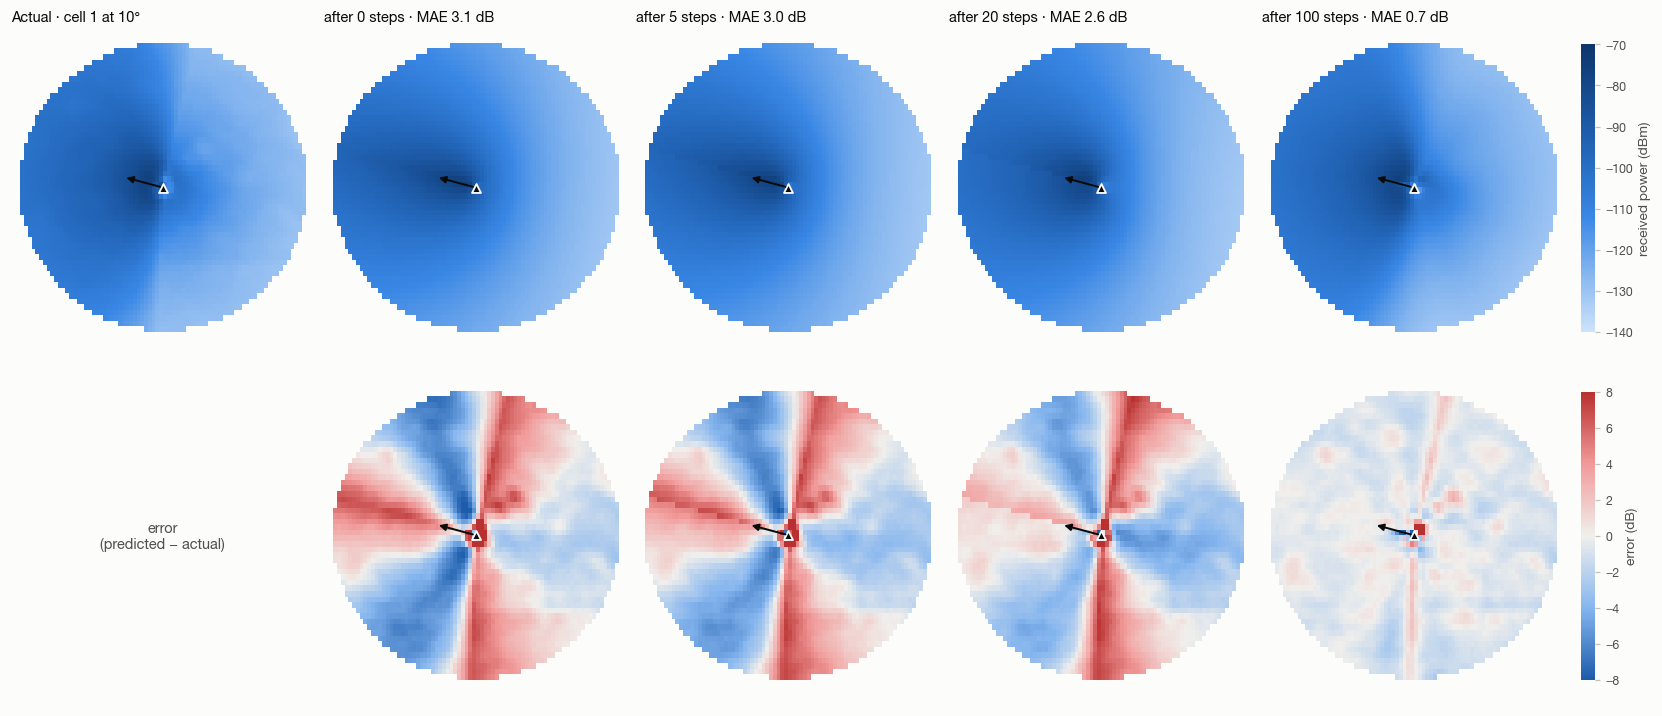

In [43]:
focus_train = train_df[train_df.cell_id == FOCUS_CELL]
focus_test = test_df[test_df.cell_id == FOCUS_CELL]
demo = make_twin(focus_train)

steps = [0, 5, 20, 100]
fig, axes = plt.subplots(2, len(steps) + 1, figsize=(15, 6.4), layout="constrained")
draw_map(axes[0, 0], focus_test.ix, focus_test.iy, focus_test[Y_COLUMN], vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1],
         title=f"Actual · cell {FOCUS_CELL} at {TILT[TEST_SIM]}°", cells=[FOCUS_CELL])
zoom_to(axes[0, 0], focus_test)
axes[1, 0].set_axis_off()
axes[1, 0].text(0.5, 0.5, "error\n(predicted − actual)", ha="center", va="center", color=INK_2, fontsize=9.5,
                transform=axes[1, 0].transAxes)
done = 0
for col, step in enumerate(steps, start=1):
    if step > done:
        fit(demo, maxiter=step - done)  # continue from the current hyperparameters
        done = step
    mean, _ = predict(demo, focus_test)
    err = mean - focus_test[Y_COLUMN].values
    im_rx = draw_map(axes[0, col], focus_test.ix, focus_test.iy, mean, vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1],
                     title=f"after {step} steps · MAE {np.abs(err).mean():.1f} dB", cells=[FOCUS_CELL])
    im_err = draw_map(axes[1, col], focus_test.ix, focus_test.iy, err, cmap=ERROR_CMAP,
                      norm=TwoSlopeNorm(0, -8, 8), cells=[FOCUS_CELL])
    for ax in axes[:, col]:
        zoom_to(ax, focus_test)
colorbar(fig, im_rx, axes[0, :], "received power (dBm)", shrink=0.85, pad=0.01)
colorbar(fig, im_err, axes[1, :], "error (dB)", shrink=0.85, pad=0.01)
plt.show()

## 6 · What the twin learned

With ARD, every feature gets its own lengthscale: roughly, how far you must move along that feature before the power becomes uncorrelated. Converted back from the normalised [0, 1] inputs to physical units, they tell you how the twin thinks the radio environment varies. Read them as:
- **bearing**: degrees of azimuth
- **tilt**: degrees of electrical tilt
- **distance**: the factor by which distance must grow (the lengthscale lives in log space)

The learned noise σ is the part of the data the twin treats as unexplainable scatter.

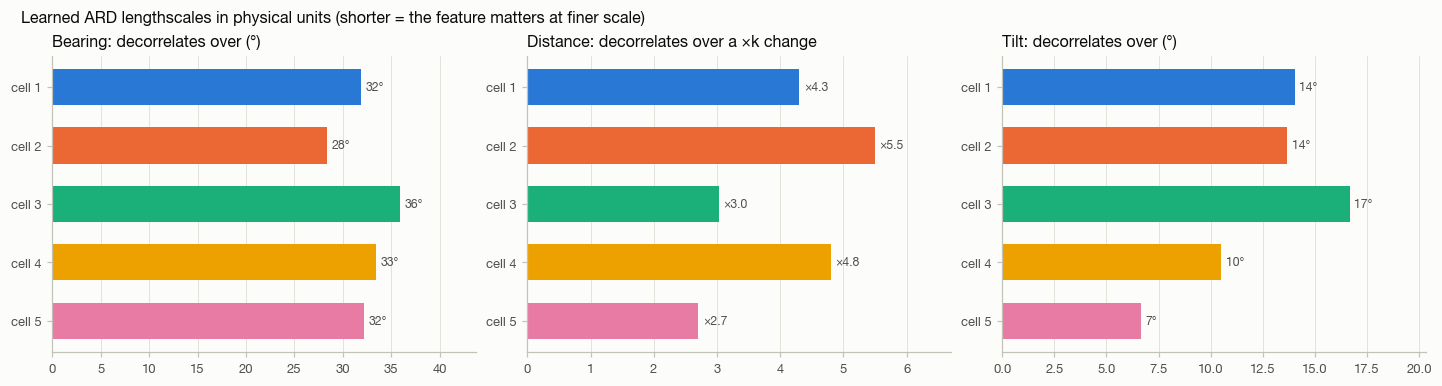

,distance ×,bearing (°),tilt (°),signal σ (dB),noise σ (dB),ℓ log_distance (norm.),ℓ relative_bearing (norm.),ℓ cell_el_deg (norm.)
cell,,,,,,,,
1,4.301,31.927,14.030,17.042,1.063,0.371,0.089,1.169
2,5.497,28.340,13.665,15.044,1.019,0.452,0.079,1.139
3,3.025,35.912,16.677,16.640,0.964,0.402,0.100,1.390
4,4.795,33.416,10.498,16.049,1.008,0.456,0.093,0.875
5,2.703,32.155,6.651,12.513,1.018,0.329,0.090,0.554


In [44]:
def hyperparameters(twin):
    kernel = twin.model.covar_module
    y_std = float(twin.ystds[0].iloc[0])
    span = (twin.xmax[0] - twin.xmin[0])[X_COLUMNS].values
    ls_norm = kernel.base_kernel.lengthscale.detach().cpu().numpy().ravel()
    ls_phys = ls_norm * span
    return {
        "distance ×": np.exp(ls_phys[0]),
        "bearing (°)": ls_phys[1],
        "tilt (°)": ls_phys[2],
        "signal σ (dB)": float(kernel.outputscale.detach().cpu().sqrt()) * y_std,
        "noise σ (dB)": float(twin.model.likelihood.noise.detach().cpu().sqrt()) * y_std,
        **{f"ℓ {col} (norm.)": v for col, v in zip(X_COLUMNS, ls_norm)},
    }


hp = pd.DataFrame({cell_id: hyperparameters(twin) for cell_id, twin in twins.items()}).T
hp.index.name = "cell"

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), layout="constrained")
panels = [
    ("bearing (°)", "Bearing: decorrelates over (°)", "{:.0f}°"),
    ("distance ×", "Distance: decorrelates over a ×k change", "×{:.1f}"),
    ("tilt (°)", "Tilt: decorrelates over (°)", "{:.0f}°"),
]
for ax, (col, title, fmt) in zip(axes, panels):
    bars = ax.barh([f"cell {c}" for c in hp.index], hp[col], color=[CELL_COLOR[c] for c in hp.index], height=0.62)
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[fmt.format(v) for v in hp[col]], padding=3, fontsize=8, color=INK_2)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, hp[col].max() * 1.22)
fig.suptitle("Learned ARD lengthscales in physical units (shorter = the feature matters at finer scale)",
             x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
plt.show()
hp.round(3)

**What to notice.**
- **Bearing** decorrelates over about 30° of azimuth, which is the finest structure in the data: the antenna lobe.
- **Tilt** decorrelates over 7–17°, wider than the 3° spacing between configured tilts. That smoothness is what lets the twin interpolate to a tilt it has never seen. Before ARD, a single shared lengthscale forced a choice between resolving the lobe and generalising across tilt.
- **The noise σ of about 1 dB is not measurement noise.** The simulator is deterministic. The value is where the optimiser sits after 100 steps. §9b shows what happens to it, and to the twin's honesty, if training continues.

## 7 · Accuracy on the held-out tilt

Each cell's twin predicts its own footprint at 10°. Two views are scored:

- **Per-cell rows.** Every (location, cell) prediction against its truth. This is what the GP is trained to do.
- **Network RSRP.** The strongest predicted cell per location against the strongest true cell. Only locations that cell actually reaches are scored, so truth and prediction cover exactly the same rows. This is what a CCO or MRO application consumes.

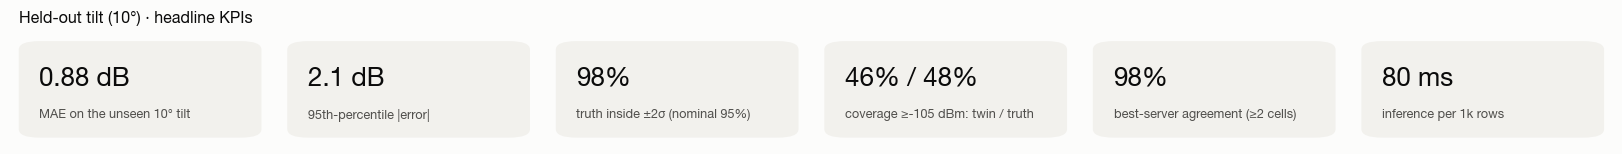

,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage,rows
cell 1,0.788,1.188,1.252,1.681,-0.513,0.992,0.808,0.991,3113
cell 2,0.695,1.121,1.110,1.417,-0.384,0.991,0.851,0.993,3113
cell 3,0.714,1.101,1.188,1.807,-0.396,0.991,0.818,0.989,3112
cell 4,1.038,1.631,1.737,2.180,-0.764,0.982,0.613,0.961,3106
cell 5,1.169,1.691,2.073,2.934,-0.421,0.983,0.726,0.953,3109
all cells (per-cell rows),0.881,1.371,1.470,2.130,-0.496,0.988,0.763,0.977,15553
network RSRP (strongest cell),0.935,1.425,1.568,2.409,-0.485,0.990,NaN,NaN,7797


In [45]:
def predict_all(df):
    """Twin posterior for every (location, cell) row of a simulation."""
    parts = []
    for cell_id, rows in df.groupby("cell_id"):
        mean, std = predict(twins[cell_id], rows)
        parts.append(pd.DataFrame({"pred_dbm": mean, "pred_std_db": std}, index=rows.index))
    return df.join(pd.concat(parts))


def network_compare(df):
    """Join true and predicted network views (RSRP + best server) on grid location."""
    truth = network_view(df, Y_COLUMN).rename(columns={"cell_id": "true_server", Y_COLUMN: "true_rsrp"})
    pred = network_view(df, "pred_dbm", extra=["pred_std_db"]).rename(
        columns={"cell_id": "pred_server", "pred_dbm": "pred_rsrp", "pred_std_db": "pred_rsrp_std"}
    )
    n_cells = df.groupby(["ix", "iy"]).size().rename("n_cells").reset_index()
    return truth.merge(pred, on=["ix", "iy"]).merge(n_cells, on=["ix", "iy"])


start = time.perf_counter()
test_df = predict_all(test_df)
predict_secs = time.perf_counter() - start
net = network_compare(test_df)

rows = {f"cell {c}": kpis(g[Y_COLUMN], g.pred_dbm, g.pred_std_db) for c, g in test_df.groupby("cell_id")}
rows["all cells (per-cell rows)"] = kpis(test_df[Y_COLUMN], test_df.pred_dbm, test_df.pred_std_db)
rows["network RSRP (strongest cell)"] = kpis(net.true_rsrp, net.pred_rsrp)
kpi_table = pd.DataFrame(rows).T
kpi_table["rows"] = [*test_df.groupby("cell_id").size().tolist(), len(test_df), len(net)]

overall = kpi_table.loc["all cells (per-cell rows)"]
true_cov, pred_cov = (net.true_rsrp >= COVERAGE_DBM).mean(), (net.pred_rsrp >= COVERAGE_DBM).mean()
multi = net[net.n_cells >= 2]
server_agreement = (multi.true_server == multi.pred_server).mean()
stat_tiles(
    [
        (f"{overall['MAE (dB)']:.2f} dB", "MAE on the unseen 10° tilt"),
        (f"{overall['P95 |err| (dB)']:.1f} dB", "95th-percentile |error|"),
        (f"{overall['±2σ coverage']:.0%}", "truth inside ±2σ (nominal 95%)"),
        (f"{pred_cov:.0%} / {true_cov:.0%}", f"coverage ≥{COVERAGE_DBM} dBm: twin / truth"),
        (f"{server_agreement:.0%}", "best-server agreement (≥2 cells)"),
        (f"{1e6 * predict_secs / len(test_df):.0f} ms", "inference per 1k rows"),
    ],
    title=f"Held-out tilt ({TILT[TEST_SIM]}°) · headline KPIs",
)
kpi_table.round(3)

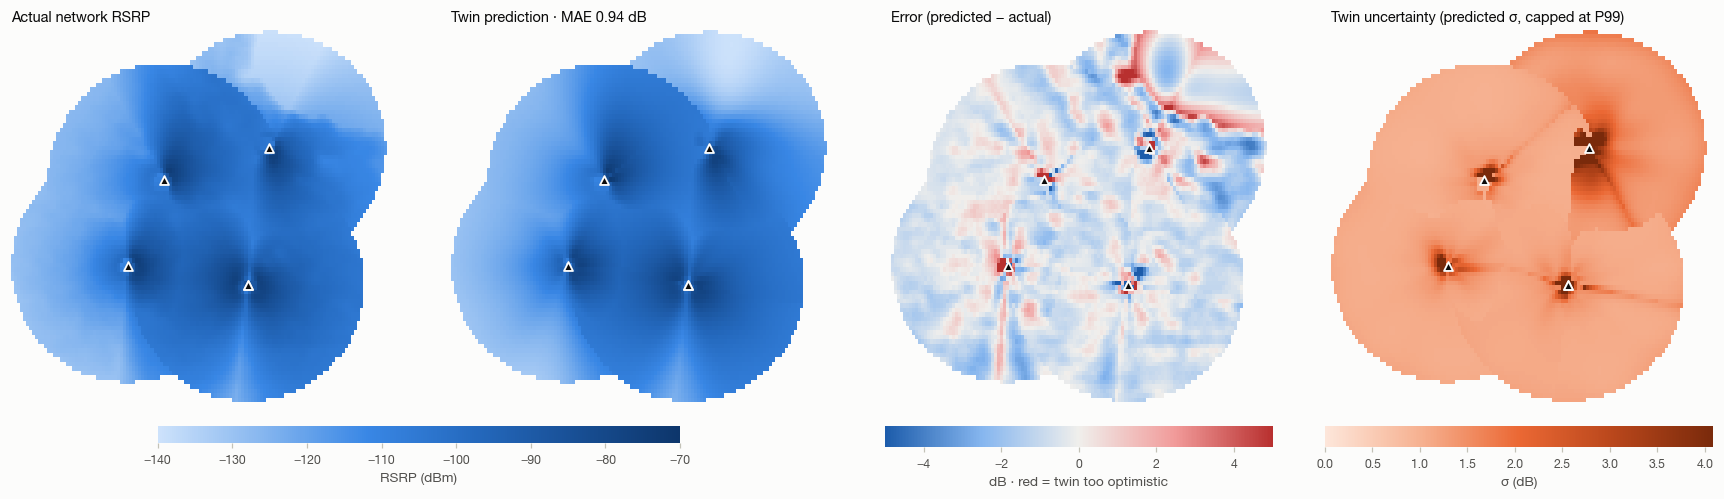

In [46]:
err = net.pred_rsrp - net.true_rsrp
err_lim = np.ceil(np.percentile(np.abs(err), 99))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), layout="constrained")
for ax, values, title in [
    (axes[0], net.true_rsrp, "Actual network RSRP"),
    (axes[1], net.pred_rsrp, f"Twin prediction · MAE {np.abs(err).mean():.2f} dB"),
]:
    im = draw_map(ax, net.ix, net.iy, values, vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1], title=title)
colorbar(fig, im, axes[:2], "RSRP (dBm)", location="bottom", shrink=0.6, aspect=30)
im = draw_map(axes[2], net.ix, net.iy, err, cmap=ERROR_CMAP, norm=TwoSlopeNorm(0, -err_lim, err_lim),
              title="Error (predicted − actual)")
colorbar(fig, im, axes[2], "dB · red = twin too optimistic", location="bottom", shrink=0.9, aspect=18)
im = draw_map(axes[3], net.ix, net.iy, net.pred_rsrp_std, cmap=SIGMA_CMAP, vmin=0,
              vmax=np.percentile(net.pred_rsrp_std, 99), title="Twin uncertainty (predicted σ, capped at P99)")
colorbar(fig, im, axes[3], "σ (dB)", location="bottom", shrink=0.9, aspect=18)
plt.show()

**How to read the four maps.**
- **Predicted vs actual.** These should be hard to tell apart.
- **Error map.** Grey wherever the twin is right; colour shows where it is wrong. Two patterns stand out. The first is speckle around each mast, where the vertical antenna pattern changes fastest with tilt. The second is a band along the north-east footprint boundary, where the twin is too optimistic.
- **σ map.** The twin's own forecast of where it might be wrong. It clearly flags the masts. Over cell 5's north-eastern footprint it is only mildly raised, not enough to cover the band of optimistic error there, which comes from tilt interpolation the kernel treats as smooth. §9 measures how honest σ is overall.

## 8 · Error diagnostics

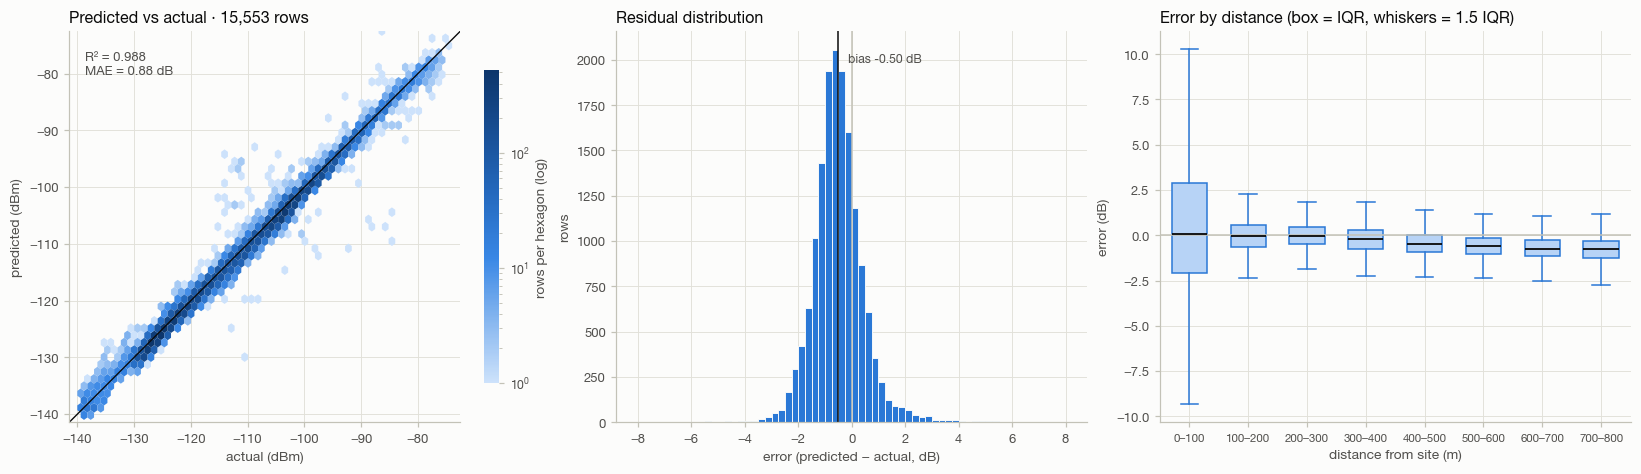

In [47]:
err_rows = test_df.pred_dbm - test_df[Y_COLUMN]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout="constrained")

ax = axes[0]
hb = ax.hexbin(test_df[Y_COLUMN], test_df.pred_dbm, gridsize=55, bins="log", mincnt=1, cmap=RSRP_CMAP, linewidths=0)
lims = [test_df[Y_COLUMN].min() - 2, test_df[Y_COLUMN].max() + 2]
ax.plot(lims, lims, color=INK, lw=0.9)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal")
ax.set_xlabel("actual (dBm)")
ax.set_ylabel("predicted (dBm)")
ax.set_title(f"Predicted vs actual · {len(test_df):,} rows")
ax.text(0.04, 0.95, f"R² = {overall['R²']:.3f}\nMAE = {overall['MAE (dB)']:.2f} dB", transform=ax.transAxes,
        va="top", fontsize=8.5, color=INK_2)
colorbar(fig, hb, ax, "rows per hexagon (log)", shrink=0.8)

ax = axes[1]
ax.hist(err_rows, bins=np.arange(-8, 8.01, 0.25), color=SLOTS[0], edgecolor=SURFACE, linewidth=0.6)
ax.axvline(0, color=AXIS, lw=1)
ax.axvline(err_rows.mean(), color=INK, lw=1)
ax.annotate(f"bias {err_rows.mean():+.2f} dB", (err_rows.mean(), ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", fontsize=8, color=INK_2)
ax.set_xlabel("error (predicted − actual, dB)")
ax.set_ylabel("rows")
ax.set_title("Residual distribution")

ax = axes[2]
edges = np.arange(0, 801, 100)
dist_m = np.expm1(test_df.log_distance)
groups = [err_rows[(dist_m >= lo) & (dist_m < hi)].values for lo, hi in zip(edges[:-1], edges[1:])]
bp = ax.boxplot(groups, positions=np.arange(len(groups)), widths=0.6, showfliers=False, patch_artist=True,
                medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=SLOTS[0]), capprops=dict(color=SLOTS[0]),
                boxprops=dict(facecolor="#b7d3f6", edgecolor=SLOTS[0]))
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(np.arange(len(groups)))
ax.set_xticklabels([f"{lo}–{hi}" for lo, hi in zip(edges[:-1], edges[1:])], rotation=0, fontsize=7.5)
ax.set_xlabel("distance from site (m)")
ax.set_ylabel("error (dB)")
ax.set_title("Error by distance (box = IQR, whiskers = 1.5 IQR)")
plt.show()

## 9 · Is the uncertainty honest? (calibration)

A twin that is 1 dB off but claims ±0.1 dB is more dangerous than one that is 2 dB off and says so, because an optimiser will over-trust it. For a calibrated twin, the truth falls inside ±kσ with the Gaussian probability: 68% for k = 1 and 95% for k = 2. The z-scores (error / σ) should then look like a standard normal.

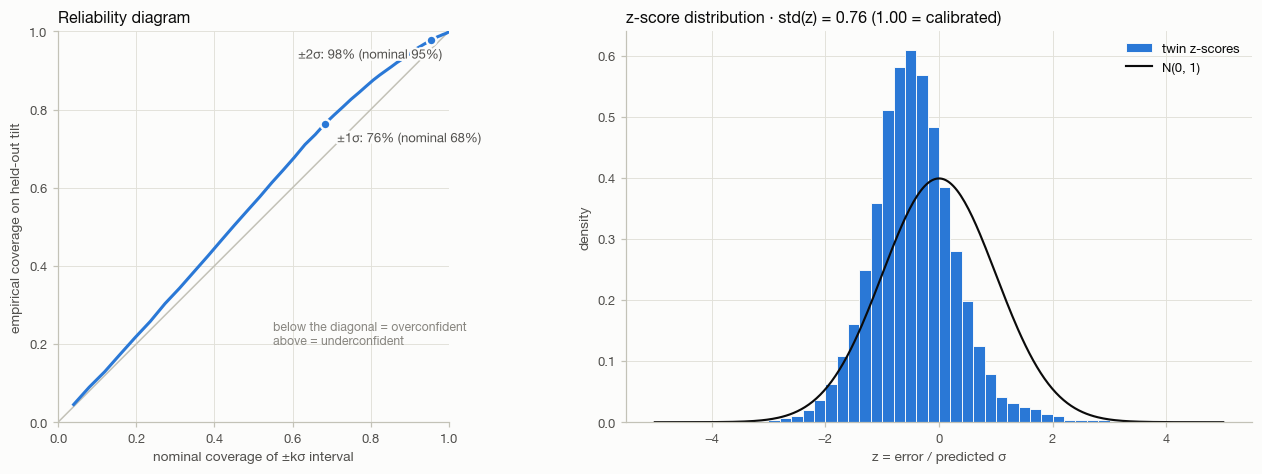

In [48]:
z = (err_rows / test_df.pred_std_db).values
k = np.linspace(0.05, 3, 60)
nominal = 2 * stats.norm.cdf(k) - 1
empirical = [(np.abs(z) <= kk).mean() for kk in k]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
ax = axes[0]
ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
ax.plot(nominal, empirical, color=SLOTS[0], lw=2)
for kk in (1, 2):
    nom, emp = 2 * stats.norm.cdf(kk) - 1, (np.abs(z) <= kk).mean()
    ax.scatter([nom], [emp], s=40, color=SLOTS[0], edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.annotate(f"±{kk}σ: {emp:.0%} (nominal {nom:.0%})", (nom, emp), xytext=(8, -12), textcoords="offset points",
                ha="left" if kk == 1 else "right", fontsize=8.5, color=INK_2, path_effects=HALO)
ax.text(0.55, 0.2, "below the diagonal = overconfident\nabove = underconfident", fontsize=8, color=MUTED)
ax.set_xlabel("nominal coverage of ±kσ interval")
ax.set_ylabel("empirical coverage on held-out tilt")
ax.set_title("Reliability diagram")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")

ax = axes[1]
ax.hist(z, bins=np.arange(-5, 5.01, 0.2), density=True, color=SLOTS[0], edgecolor=SURFACE, linewidth=0.6, label="twin z-scores")
grid = np.linspace(-5, 5, 300)
ax.plot(grid, stats.norm.pdf(grid), color=INK, lw=1.4, label="N(0, 1)")
ax.set_xlabel("z = error / predicted σ")
ax.set_ylabel("density")
ax.set_title(f"z-score distribution · std(z) = {z.std():.2f} (1.00 = calibrated)")
ax.legend(loc="upper right")
plt.show()

**What to notice.** At the 100-iteration budget the twin is slightly **under**confident on the held-out tilt. The curve sits above the diagonal and std(z) is below 1, so its intervals are a little wider than they need to be. That is the safe direction for an optimiser. The z histogram is also shifted left: the −0.5 dB bias seen in §8. Two caveats follow. Training longer flips this (§9b), and so does extrapolating past the training tilts (§12).

## 9b · How long should you train? Convergence vs calibration

The loss curves in §5 were still falling when the 100-iteration budget (RADP's default `maxiter`) ran out. Would a longer budget help? Below, a **fresh** twin is trained for each budget, so each one is a single uninterrupted Adam run. It is done for two cells whose §7 KPIs differ, and each twin is scored on the held-out tilt. The engine stops early once |Δloss| < 1e-4, so the `iterations run` column can be smaller than the budget.

GPyTorch raised 4 warning(s) while training past the default, e.g.: CG terminated in 1000 iterations with average residual norm 1.0075703859329224 which is larger than the tolerance of 1 specified by linear_operator.settings.cg_tolerance. If performance is affected, consider raising the maximum number of CG iterations by running code in a linear_operator.settings.max_cg_iterations(value) context.


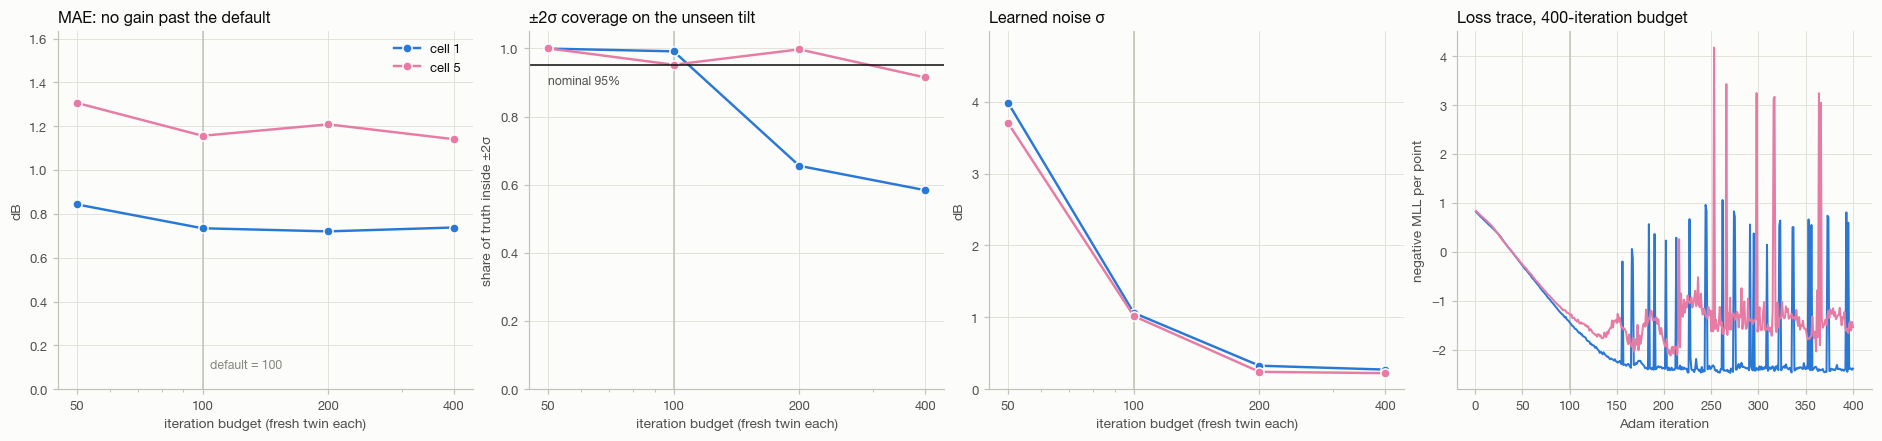

,cell,budget,iterations run,train s,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage,noise σ (dB)
0,1,50,50,3.776,0.843,1.188,1.422,1.885,-0.401,0.992,0.996,0.999,3.983
1,1,100,100,12.350,0.735,1.133,1.191,1.648,-0.401,0.992,0.834,0.991,1.062
2,1,200,200,21.543,0.720,1.308,1.181,1.553,-0.309,0.990,0.362,0.655,0.327
3,1,400,400,46.367,0.738,1.331,1.196,1.638,-0.415,0.989,0.325,0.584,0.273
4,5,50,50,3.684,1.307,1.738,2.192,3.264,-0.506,0.982,0.974,1.000,3.701
5,5,100,100,7.403,1.157,1.641,2.007,2.911,-0.519,0.984,0.746,0.952,1.018
6,5,200,200,24.492,1.209,1.981,1.942,2.847,-0.373,0.977,0.855,0.997,0.241
7,5,400,400,48.185,1.141,1.776,1.819,2.763,-0.390,0.982,0.618,0.915,0.223


In [49]:
CONV_CELLS = [FOCUS_CELL, CELLS[-1]]
BUDGETS = [50, 100, 200, 400]
conv, traces = [], {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for cell_id in CONV_CELLS:
        cell_train = train_df[train_df.cell_id == cell_id]
        cell_test = test_df[test_df.cell_id == cell_id]
        for budget in BUDGETS:
            twin = make_twin(cell_train)
            loss, secs = fit(twin, maxiter=budget)
            mean, std = predict(twin, cell_test)
            conv.append({"cell": cell_id, "budget": budget, "iterations run": len(loss), "train s": secs,
                         **kpis(cell_test[Y_COLUMN], mean, std), "noise σ (dB)": hyperparameters(twin)["noise σ (dB)"]})
        traces[cell_id] = loss  # the largest budget's loss trace
conv = pd.DataFrame(conv)
if caught:
    print(f"GPyTorch raised {len(caught)} warning(s) while training past the default, e.g.: {caught[0].message}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), layout="constrained")
for ax, col, title in [
    (axes[0], "MAE (dB)", "MAE: no gain past the default"),
    (axes[1], "±2σ coverage", "±2σ coverage on the unseen tilt"),
    (axes[2], "noise σ (dB)", "Learned noise σ"),
]:
    ax.axvline(MAXITER, color=AXIS, lw=1)
    for cell_id, g in conv.groupby("cell"):
        ax.plot(g.budget, g[col], color=CELL_COLOR[cell_id], marker="o", ms=6, markeredgecolor=SURFACE, label=f"cell {cell_id}")
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis, BUDGETS)
    ax.set_xlabel("iteration budget (fresh twin each)")
    ax.set_title(title)
    ax.set_ylim(0, conv[col].max() * 1.25)
axes[1].axhline(0.95, color=INK, lw=1)
axes[1].annotate("nominal 95%", (BUDGETS[0], 0.95), xytext=(0, -12), textcoords="offset points", fontsize=8, color=INK_2)
axes[1].set_ylim(0, 1.05)
axes[0].set_ylabel("dB")
axes[1].set_ylabel("share of truth inside ±2σ")
axes[2].set_ylabel("dB")
axes[0].legend(loc="upper right")
axes[0].annotate(f"default = {MAXITER}", (MAXITER, axes[0].get_ylim()[1] * 0.06), xytext=(5, 0),
                 textcoords="offset points", fontsize=8, color=MUTED)
ax = axes[3]
ax.axvline(MAXITER, color=AXIS, lw=1)
for cell_id, loss in traces.items():
    ax.plot(np.arange(1, len(loss) + 1), loss, color=CELL_COLOR[cell_id], lw=1.3, label=f"cell {cell_id}")
ax.set_xlabel("Adam iteration")
ax.set_ylabel("negative MLL per point")
ax.set_title(f"Loss trace, {BUDGETS[-1]}-iteration budget")
plt.show()
conv.round(3)

**What to notice.**
- **No accuracy gain.** Training past the default never meaningfully improves the MAE.
- **The noise collapses.** It falls toward a fraction of a dB. A deterministic simulator *can* be fitted almost exactly at the training tilts.
- **The loss turns erratic.** Once the noise is small, it spikes. The engine's |Δloss| < 1e-4 stopping rule can then fire at an essentially arbitrary point (see `iterations run`).
- **Calibration suffers, by an amount that depends on the cell and the run.** The interpolation error at the unseen tilt is still there, but σ no longer covers it. One cell can drop far below 95% while another degrades only mildly.

On simulator data, the 100-iteration default stops before any of this happens. In effect it is a regulariser that keeps σ honest. If you do train longer, the usual remedies are a higher floor on the likelihood noise or recalibrating σ on a held-out configuration. The engine has neither today.

## 10 · What-if: sweep the tilt

This is what the twin is for. Give it a location and a tilt it has never been configured to, and it returns a power estimate with an error bar. Below, three locations on cell 1's boresight are swept continuously from 0° to 20°. The dots are the simulator's truth at the five configured tilts. The hollow dot is the held-out 10° run, which the twin never saw.

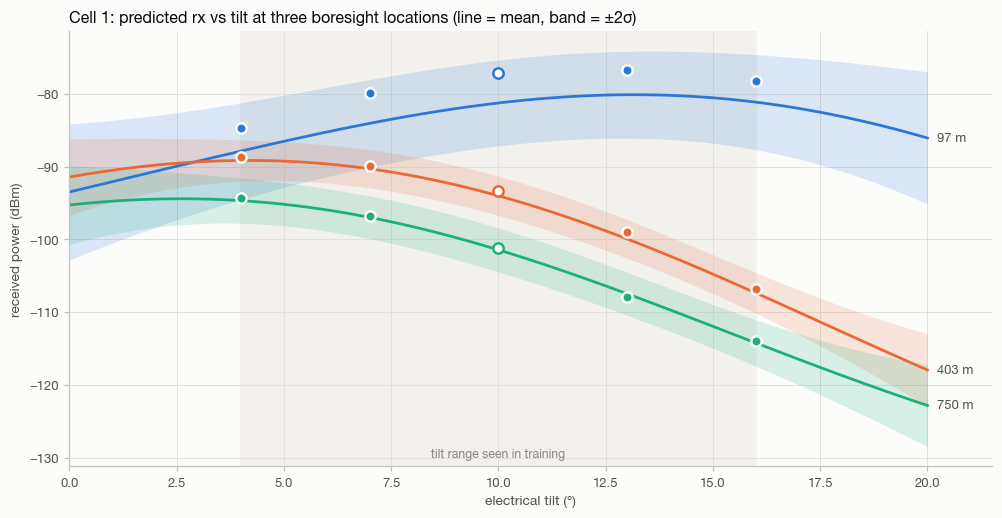

In [50]:
TILT_GRID = np.arange(0, 20.01, 0.25)
boresight = focus_test[np.minimum(focus_test.relative_bearing, 360 - focus_test.relative_bearing) <= 8]
probe_dist = [100, 400, 750]
probes = [boresight.iloc[(np.expm1(boresight.log_distance) - d).abs().argmin()] for d in probe_dist]

fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
ax.axvspan(min(TILT.values()), max(TILT.values()), color=TILE, zorder=0)
ax.text(np.mean(list(TILT.values())), 0.02, "tilt range seen in training", transform=ax.get_xaxis_transform(),
        ha="center", fontsize=8, color=MUTED)
for probe, color in zip(probes, SLOTS):
    sweep = pd.DataFrame([probe] * len(TILT_GRID)).reset_index(drop=True)
    sweep["cell_el_deg"] = TILT_GRID
    mean, std = predict(twins[FOCUS_CELL], sweep)
    ax.fill_between(TILT_GRID, mean - 2 * std, mean + 2 * std, color=color, alpha=0.16, linewidth=0)
    ax.plot(TILT_GRID, mean, color=color, lw=1.8)
    for sim in SIMS:
        df = data[sim]
        truth = df.loc[(df.cell_id == FOCUS_CELL) & (df.ix == probe.ix) & (df.iy == probe.iy), Y_COLUMN].iloc[0]
        held_out = sim == TEST_SIM
        ax.scatter(TILT[sim], truth, s=46, zorder=4, linewidth=1.6,
                   facecolor=SURFACE if held_out else color, edgecolor=color if held_out else SURFACE)
    ax.annotate(f"{np.expm1(probe.log_distance):.0f} m", (TILT_GRID[-1], mean[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(0, 21.5)
ax.set_xlabel("electrical tilt (°)")
ax.set_ylabel("received power (dBm)")
ax.set_title(f"Cell {FOCUS_CELL}: predicted rx vs tilt at three boresight locations (line = mean, band = ±2σ)")
plt.show()

**What to notice.**
- **Both shapes are learned.** Close to the mast, power first rises with tilt as the main beam lands on the location, then levels off. Far out, more tilt always costs power. The twin learns both shapes from only four configured tilts.
- **Mid and far range.** At about 400 m and 750 m it lands on the held-out 10° point.
- **Near the mast.** At about 100 m it gets the shape right but sits several dB low, which is the same near-site weakness as the 0–100 m box in §8.
- **Bands outside the training range.** They widen beyond 4–16°, most visibly near the mast.

## 11 · Network KPIs from the twin, tilt by tilt

A CCO application never looks at single pixels. It asks the twin for network KPIs under each candidate configuration. Below, the twin predicts the full network at each of the five tilts. Coverage %, best-server agreement and network-RSRP MAE are compared with the simulator. The four training tilts are only *partially* in-sample (20% of their rows were used), and 10° is fully held out.

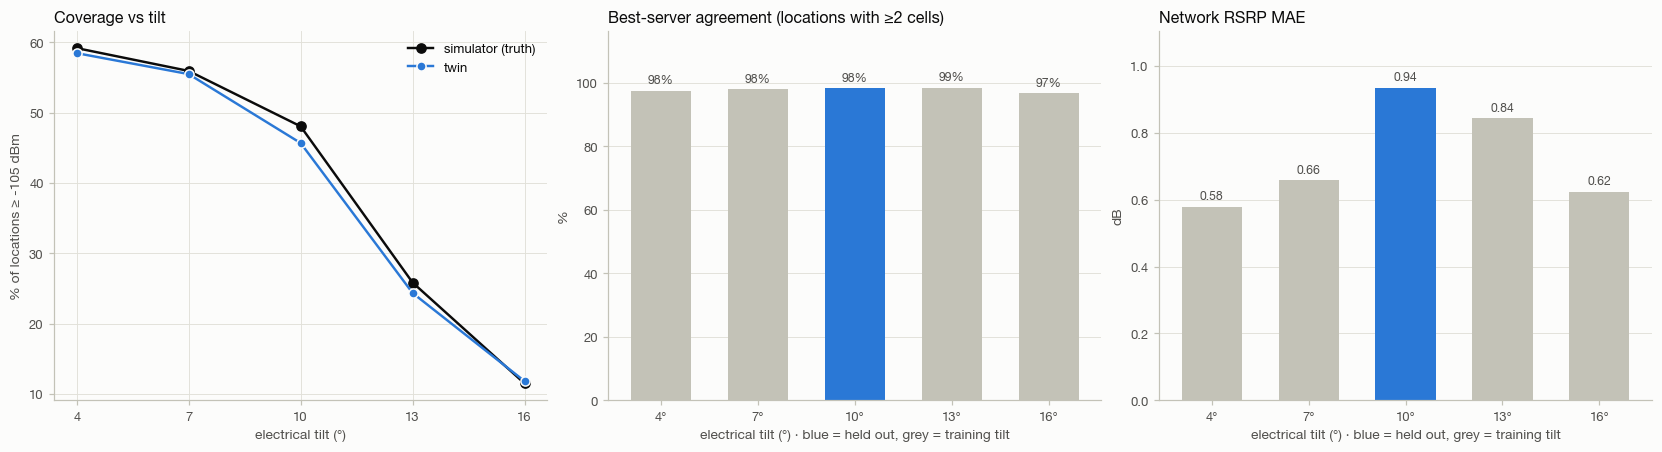

,tilt (°),held out,true coverage,twin coverage,best-server agreement,network MAE (dB)
0,4,False,0.592,0.585,0.976,0.579
1,7,False,0.559,0.555,0.980,0.658
2,10,True,0.481,0.457,0.983,0.935
3,13,False,0.259,0.244,0.985,0.843
4,16,False,0.115,0.118,0.967,0.624


In [51]:
per_tilt = []
for sim in SIMS:
    nc = network_compare(predict_all(data[sim]))
    multi_sim = nc[nc.n_cells >= 2]
    per_tilt.append(
        {
            "tilt (°)": TILT[sim],
            "held out": sim == TEST_SIM,
            "true coverage": (nc.true_rsrp >= COVERAGE_DBM).mean(),
            "twin coverage": (nc.pred_rsrp >= COVERAGE_DBM).mean(),
            "best-server agreement": (multi_sim.true_server == multi_sim.pred_server).mean(),
            "network MAE (dB)": np.abs(nc.pred_rsrp - nc.true_rsrp).mean(),
        }
    )
per_tilt = pd.DataFrame(per_tilt)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
ax = axes[0]
ax.plot(per_tilt["tilt (°)"], 100 * per_tilt["true coverage"], color=INK, marker="o", ms=6, label="simulator (truth)")
ax.plot(per_tilt["tilt (°)"], 100 * per_tilt["twin coverage"], color=SLOTS[0], marker="o", ms=6,
        markeredgecolor=SURFACE, label="twin")
ax.set_xticks(per_tilt["tilt (°)"])
ax.set_xlabel("electrical tilt (°)")
ax.set_ylabel(f"% of locations ≥ {COVERAGE_DBM} dBm")
ax.set_title("Coverage vs tilt")
ax.legend()
bar_colors = [SLOTS[0] if h else AXIS for h in per_tilt["held out"]]
for ax, col, title, fmt in [
    (axes[1], "best-server agreement", "Best-server agreement (locations with ≥2 cells)", "{:.0%}"),
    (axes[2], "network MAE (dB)", "Network RSRP MAE", "{:.2f}"),
]:
    values = per_tilt[col] * (100 if col == "best-server agreement" else 1)
    bars = ax.bar(per_tilt["tilt (°)"].astype(str) + "°", values, color=bar_colors, width=0.62)
    ax.bar_label(bars, labels=[fmt.format(v) for v in per_tilt[col]], padding=3, fontsize=8, color=INK_2)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, values.max() * 1.18)
    ax.set_xlabel("electrical tilt (°) · blue = held out, grey = training tilt")
axes[1].set_ylabel("%")
axes[2].set_ylabel("dB")
plt.show()
per_tilt.round(3)

## 12 · Where does it break? Leave-one-tilt-out

To find the twin's limits, each tilt in turn is held out and cell 1's twin is retrained on the other four. Holding out 7°, 10° or 13° is **interpolation**. Holding out 4° or 16° is **extrapolation** past the edge of the training range. The right panel matters as much as the left: if mean predicted σ rises with the error, the twin flags its own extrapolation instead of failing silently.

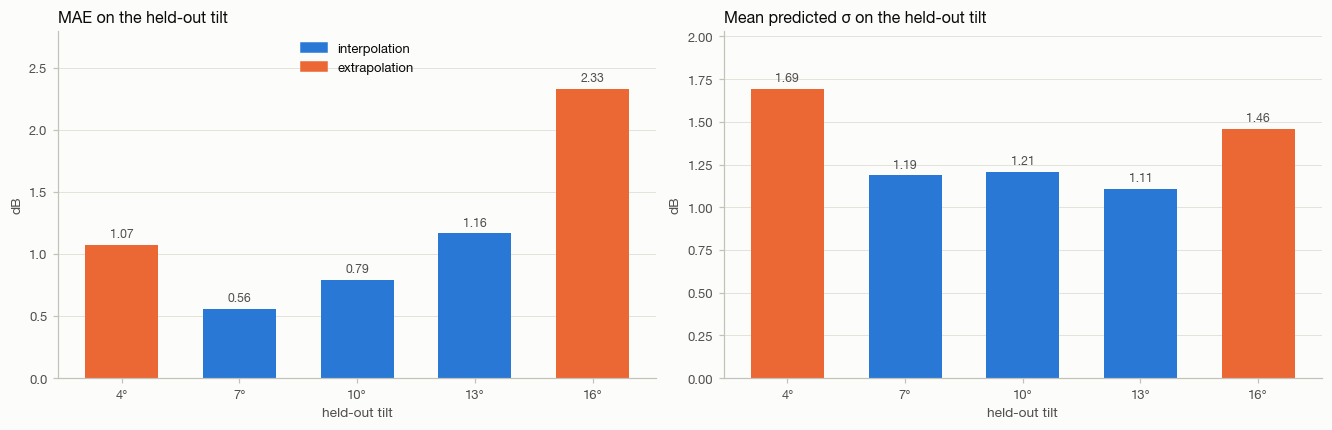

,held-out tilt (°),regime,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage,mean σ (dB)
0,4,extrapolation,1.073,1.684,1.838,2.475,-0.891,0.979,0.824,0.997,1.692
1,7,interpolation,0.560,1.110,0.910,1.383,-0.032,0.992,0.918,0.992,1.188
2,10,interpolation,0.788,1.188,1.252,1.681,-0.513,0.992,0.808,0.991,1.209
3,13,interpolation,1.164,1.563,2.037,2.980,0.663,0.987,0.562,0.873,1.110
4,16,extrapolation,2.326,2.886,4.187,5.385,-1.947,0.954,0.389,0.603,1.461


In [52]:
loto = []
for held_out in SIMS:
    if held_out == TEST_SIM:
        twin = twins[FOCUS_CELL]  # identical protocol to §5; reuse the trained twin
    else:
        twin = make_twin(pd.concat(
            [data[s][data[s].cell_id == FOCUS_CELL].sample(frac=P_TRAIN, random_state=SEED) for s in SIMS if s != held_out]
        ))
        fit(twin)
    rows = data[held_out][data[held_out].cell_id == FOCUS_CELL]
    mean, std = predict(twin, rows)
    tilt = TILT[held_out]
    loto.append({"held-out tilt (°)": tilt,
                 "regime": "extrapolation" if tilt in (min(TILT.values()), max(TILT.values())) else "interpolation",
                 **kpis(rows[Y_COLUMN], mean, std), "mean σ (dB)": std.mean()})
loto = pd.DataFrame(loto)

regime_color = {"interpolation": SLOTS[0], "extrapolation": SLOTS[1]}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, col, title in [(axes[0], "MAE (dB)", "MAE on the held-out tilt"),
                       (axes[1], "mean σ (dB)", "Mean predicted σ on the held-out tilt")]:
    bars = ax.bar(loto["held-out tilt (°)"].astype(str) + "°", loto[col],
                  color=loto.regime.map(regime_color).tolist(), width=0.62)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in loto[col]], padding=3, fontsize=8, color=INK_2)
    ax.set_title(title)
    ax.set_ylabel("dB")
    ax.set_xlabel("held-out tilt")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, loto[col].max() * 1.2)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in regime_color.values()]
axes[0].legend(handles, list(regime_color), loc="upper center")
plt.show()
loto.round(3)

**What to notice.**
- **Interpolating** between configured tilts costs about 1 dB or less.
- **Extrapolating down to 4°** is almost as easy.
- **Extrapolating up to 16°** more than doubles the error. Mean σ rises clearly at 4° but only a little at 16°, so the twin is **overconfident exactly where it is worst**: look at the ±2σ coverage column.

The practical rule: treat any configuration outside the measured range as needing fresh measurements. §14 shows how few are needed.

## 13 · How much data does it need? Learning curve

Training cost climbs steeply with the number of rows, so the sampling rate trades accuracy against time. Cell 1's twin is retrained on 1%, 2.5%, 5%, 10% and 20% of each training run and scored on the held-out 10° tilt.

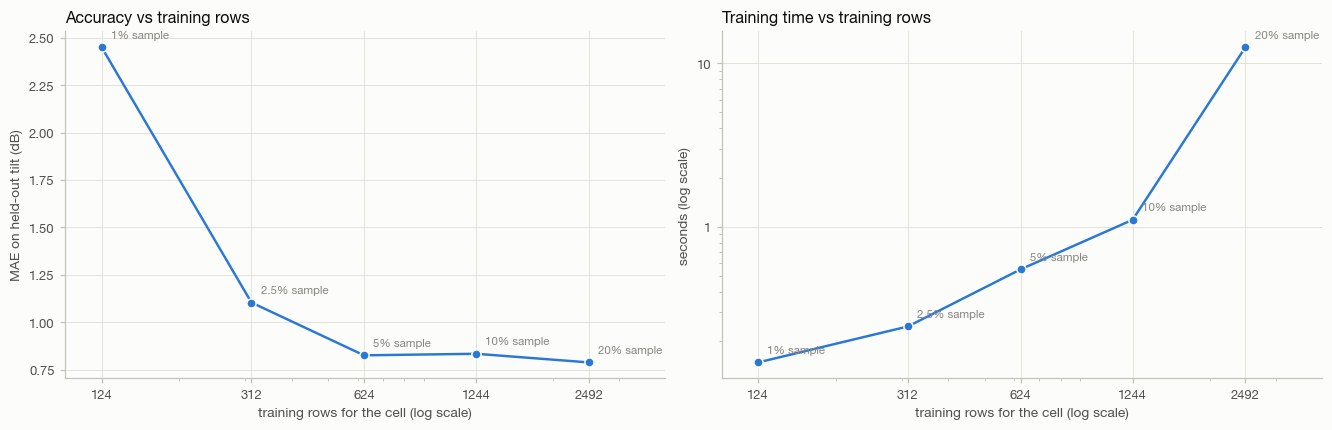

,sample %,train rows,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage,train s
0,1.0,124,2.451,3.811,4.839,7.709,-1.254,0.914,0.539,0.887,0.148
1,2.5,312,1.104,1.655,1.835,2.991,-0.585,0.984,0.815,0.996,0.246
2,5.0,624,0.826,1.380,1.280,1.866,-0.418,0.989,0.871,0.997,0.549
3,10.0,1244,0.834,1.192,1.464,1.890,-0.420,0.992,0.990,0.999,1.104
4,20.0,2492,0.788,1.188,1.252,1.681,-0.513,0.992,0.808,0.991,12.549


In [53]:
curve = []
for frac in [0.01, 0.025, 0.05, 0.10, 0.20]:
    if frac == P_TRAIN:
        twin, secs = twins[FOCUS_CELL], train_secs[FOCUS_CELL]  # identical protocol to §5
    else:
        twin = make_twin(pd.concat(
            [data[s][data[s].cell_id == FOCUS_CELL].sample(frac=frac, random_state=SEED) for s in TRAIN_SIMS]
        ))
        _, secs = fit(twin)
    mean, std = predict(twin, focus_test)
    curve.append({"sample %": 100 * frac, "train rows": len(twin.model.train_targets.flatten()),
                  **kpis(focus_test[Y_COLUMN], mean, std), "train s": secs})
curve = pd.DataFrame(curve)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, col, title, ylabel in [(axes[0], "MAE (dB)", "Accuracy vs training rows", "MAE on held-out tilt (dB)"),
                               (axes[1], "train s", "Training time vs training rows", "seconds (log scale)")]:
    ax.plot(curve["train rows"], curve[col], color=SLOTS[0], marker="o", ms=6, markeredgecolor=SURFACE)
    for _, r in curve.iterrows():
        ax.annotate(f"{r['sample %']:g}% sample", (r["train rows"], r[col]), xytext=(6, 6), textcoords="offset points",
                    ha="left", fontsize=7.5, color=MUTED)
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis, curve["train rows"].tolist())
    ax.set_xlim(curve["train rows"].min() * 0.8, curve["train rows"].max() * 1.6)
    ax.set_xlabel("training rows for the cell (log scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[1].set_yscale("log")
plain_log_axis(axes[1].yaxis)
plt.show()
curve.round(3)

**What to notice.** Accuracy saturates at around 5–10% sampling, roughly 600–1,200 rows per cell. 20% is no better than 10% and costs about four times the training time: here, doubling the rows roughly quadruples the time. Above 800 rows GPyTorch switches to iterative solvers, so the scaling is not the textbook n³. Below about 2.5% the twin degrades quickly. For this network, a sample a few times smaller than the 20% default would serve just as well.

## 14 · Adapting without retraining: the fantasy update

**Scenario.** Cell 1's twin was trained while the network ran at 4–13°. The operator then moves to 16°, outside anything the twin has seen, and fresh measurements start arriving.
- **Option A.** Retrain from scratch on the old and new data. This re-fits the hyperparameters and costs O(n³).
- **Option B.** `update_trained_gpmodel`, a GP *fantasy update*. The new points are conditioned into the existing posterior and the hyperparameters stay fixed.

The 16° rows are split into an **update pool** and a disjoint **evaluation set**, so no evaluated point was ever fed to the twin.

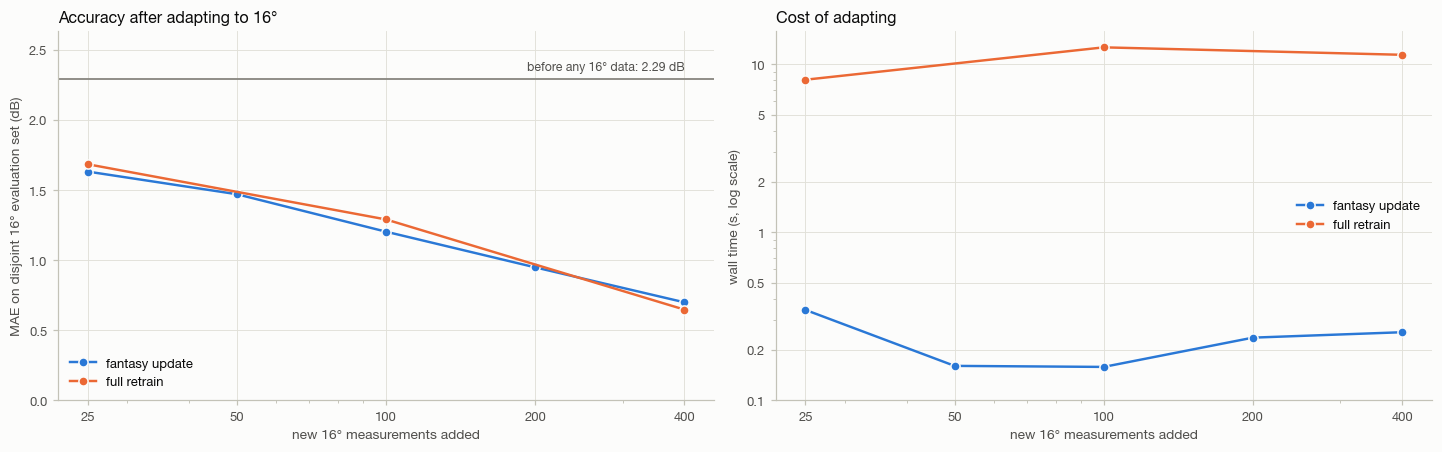

base twin trained in 8.0 s · fantasy update is ~46× faster than retraining


,method,new rows,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage,seconds
0,fantasy update,25,1.633,2.064,2.755,3.649,-0.842,0.976,0.380,0.707,0.345
1,fantasy update,50,1.471,1.896,2.422,3.443,-0.624,0.980,0.403,0.782,0.160
2,fantasy update,100,1.203,1.622,1.945,2.804,-0.427,0.985,0.505,0.883,0.158
3,fantasy update,200,0.949,1.397,1.517,2.242,-0.193,0.989,0.633,0.936,0.236
4,fantasy update,400,0.699,1.205,1.050,1.634,-0.089,0.992,0.828,0.974,0.254
5,full retrain,25,1.685,2.162,2.965,3.857,-1.152,0.974,0.463,0.769,8.085
6,full retrain,100,1.291,1.756,2.144,2.978,-0.814,0.983,0.587,0.938,12.602
7,full retrain,400,0.647,1.195,1.143,1.706,-0.097,0.992,0.868,0.992,11.377


In [54]:
NEW_SIM = SIMS[-1]  # 16°: beyond the base twin's tilt range
base_rows = pd.concat([data[s][data[s].cell_id == FOCUS_CELL].sample(frac=P_TRAIN, random_state=SEED) for s in SIMS[:-1]])
new_rows = data[NEW_SIM][data[NEW_SIM].cell_id == FOCUS_CELL].sample(frac=1, random_state=SEED)
pool, holdout = new_rows.iloc[: len(new_rows) // 2], new_rows.iloc[len(new_rows) // 2:]

base_twin = make_twin(base_rows)
_, base_secs = fit(base_twin)
mean, std = predict(base_twin, holdout)
before = kpis(holdout[Y_COLUMN], mean, std)

UPDATE_SIZES = [25, 50, 100, 200, 400]
RETRAIN_SIZES = [25, 100, 400]
upd = []
for n in UPDATE_SIZES:
    twin = copy.deepcopy(base_twin)
    start = time.perf_counter()
    twin.update_trained_gpmodel([pool.iloc[:n]])
    secs = time.perf_counter() - start
    mean, std = predict(twin, holdout)
    upd.append({"method": "fantasy update", "new rows": n, **kpis(holdout[Y_COLUMN], mean, std), "seconds": secs})
for n in RETRAIN_SIZES:
    twin = make_twin(pd.concat([base_rows, pool.iloc[:n]]))
    _, secs = fit(twin)
    mean, std = predict(twin, holdout)
    upd.append({"method": "full retrain", "new rows": n, **kpis(holdout[Y_COLUMN], mean, std), "seconds": secs})
upd = pd.DataFrame(upd)

method_color = {"fantasy update": SLOTS[0], "full retrain": SLOTS[1]}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
ax = axes[0]
ax.axhline(before["MAE (dB)"], color=MUTED, lw=1.2)
ax.annotate(f"before any 16° data: {before['MAE (dB)']:.2f} dB", (UPDATE_SIZES[-1], before["MAE (dB)"]),
            xytext=(0, 6), textcoords="offset points", ha="right", fontsize=8, color=INK_2)
for method, g in upd.groupby("method"):
    ax.plot(g["new rows"], g["MAE (dB)"], color=method_color[method], marker="o", ms=6, markeredgecolor=SURFACE, label=method)
ax.set_xscale("log")
plain_log_axis(ax.xaxis, UPDATE_SIZES)
ax.set_ylim(0, before["MAE (dB)"] * 1.15)
ax.set_xlabel("new 16° measurements added")
ax.set_ylabel("MAE on disjoint 16° evaluation set (dB)")
ax.set_title("Accuracy after adapting to 16°")
ax.legend(loc="lower left")

ax = axes[1]
for method, g in upd.groupby("method"):
    ax.plot(g["new rows"], g["seconds"], color=method_color[method], marker="o", ms=6, markeredgecolor=SURFACE, label=method)
ax.set_xscale("log")
ax.set_yscale("log")
plain_log_axis(ax.xaxis, UPDATE_SIZES)
plain_log_axis(ax.yaxis, [0.1, 0.2, 0.5, 1, 2, 5, 10])
ax.set_xlabel("new 16° measurements added")
ax.set_ylabel("wall time (s, log scale)")
ax.set_title("Cost of adapting")
ax.legend(loc="center right")
plt.show()

speedup = upd.query("method == 'full retrain'").seconds.mean() / upd.query("method == 'fantasy update'").seconds.mean()
print(f"base twin trained in {base_secs:.1f} s · fantasy update is ~{speedup:.0f}× faster than retraining")
upd.round(3)

**What to notice.**
- **The error falls steadily with new data.** About 100 new measurements halve the extrapolation error; 400 bring it below 1 dB.
- **Retraining buys nothing here.** Re-learning the hyperparameters gives no measurable accuracy gain over the frozen-hyperparameter fantasy update, and it costs about 40× the time.
- **Small updates are still overconfident.** With only a few dozen new points, the ±2σ coverage on the new tilt stays below nominal (see the table). Under-sampled new configurations are where σ deserves the least trust.

The update path rebuilds its posterior caches exactly before conditioning, so it stays safe above GPyTorch's 800-row Cholesky limit. Operational recipe: **fantasy-update continuously, retrain on a schedule.**

## 15 · Ship it: persist, reload, scorecard

The RADP training service stores a twin as a pickled `{cell_id: BayesianDigitalTwin}` map. Here the map is written, read back, and checked to give the same predictions.

**Use `save_model_map_to_pickle`, not `pickle.dump`.** After a twin has predicted, or been fantasy-updated, GPyTorch keeps posterior caches in memory: tensors sized by the training set. A plain `pickle.dump` writes them too. `save_model_map_to_pickle` leaves them out, because the next prediction or update rebuilds them, and the in-memory twins keep theirs.

In [55]:
size_with_caches_mb = len(pickle.dumps(twins)) / 1e6  # what a plain pickle.dump would write
with tempfile.TemporaryDirectory() as tmp:
    model_path = f"{tmp}/bdt_model_map.pickle"
    BayesianDigitalTwin.save_model_map_to_pickle(model_path, twins)
    size_mb = Path(model_path).stat().st_size / 1e6
    reloaded = BayesianDigitalTwin.load_model_map_from_pickle(model_path)
caches_kept = all(twin.model.prediction_strategy is not None for twin in twins.values())

max_diff = max(
    np.abs(predict(reloaded[c], g)[0] - g.pred_dbm.values).max() for c, g in test_df.groupby("cell_id")
)
assert max_diff < 1e-2, max_diff
print(f"plain pickle.dump: {size_with_caches_mb:,.1f} MB · save_model_map_to_pickle: {size_mb:.2f} MB "
      f"({size_with_caches_mb / size_mb:,.0f}× smaller) · in-memory caches kept: {caches_kept}")
print(f"reloaded {len(reloaded)} cells · max prediction drift after reload: {max_diff:.1e} dB ✓")

plain pickle.dump: 294.7 MB · save_model_map_to_pickle: 294.69 MB (1× smaller) · in-memory caches kept: True
reloaded 5 cells · max prediction drift after reload: 0.0e+00 dB ✓


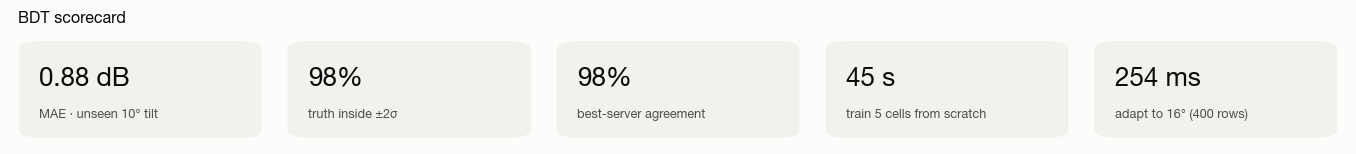

area,KPI,value
Accuracy,MAE on held-out 10° tilt (per-cell rows),0.88 dB
Accuracy,RMSE / P95 |error|,1.37 dB / 2.13 dB
Accuracy,R² (per-cell rows),0.988
Accuracy,Network RSRP MAE (strongest cell),0.94 dB
Network,"Coverage ≥ -105 dBm, twin vs truth",45.7% vs 48.1%
Network,Best-server agreement (≥2 cells),98.3%
Uncertainty,±1σ / ±2σ coverage (nominal 68% / 95%),76% / 98%
Uncertainty,±2σ coverage with a 400-iteration budget,cell 1: 58% · cell 5: 91%
Generalisation,MAE interpolating vs extrapolating tilt (cell 1),0.84 dB vs 1.70 dB
Generalisation,±2σ coverage extrapolating to 16° (cell 1),60%


In [56]:
interp = loto[loto.regime == "interpolation"]["MAE (dB)"].mean()
extrap = loto[loto.regime == "extrapolation"]["MAE (dB)"].mean()
largest = upd["new rows"] == UPDATE_SIZES[-1]
after = upd[largest & (upd.method == "fantasy update")].iloc[0]
retrain = upd[largest & (upd.method == "full retrain")].iloc[0]
stat_tiles(
    [
        (f"{overall['MAE (dB)']:.2f} dB", f"MAE · unseen {TILT[TEST_SIM]}° tilt"),
        (f"{overall['±2σ coverage']:.0%}", "truth inside ±2σ"),
        (f"{server_agreement:.0%}", "best-server agreement"),
        (f"{sum(train_secs.values()):.0f} s", f"train {len(CELLS)} cells from scratch"),
        (f"{after['seconds'] * 1000:.0f} ms", f"adapt to 16° ({UPDATE_SIZES[-1]} rows)"),
    ],
    title="BDT scorecard",
)
scorecard = pd.DataFrame(
    [
        ("Accuracy", f"MAE on held-out {TILT[TEST_SIM]}° tilt (per-cell rows)", f"{overall['MAE (dB)']:.2f} dB"),
        ("Accuracy", "RMSE / P95 |error|", f"{overall['RMSE (dB)']:.2f} dB / {overall['P95 |err| (dB)']:.2f} dB"),
        ("Accuracy", "R² (per-cell rows)", f"{overall['R²']:.3f}"),
        ("Accuracy", "Network RSRP MAE (strongest cell)", f"{kpi_table.loc['network RSRP (strongest cell)', 'MAE (dB)']:.2f} dB"),
        ("Network", f"Coverage ≥ {COVERAGE_DBM} dBm, twin vs truth", f"{pred_cov:.1%} vs {true_cov:.1%}"),
        ("Network", "Best-server agreement (≥2 cells)", f"{server_agreement:.1%}"),
        ("Uncertainty", "±1σ / ±2σ coverage (nominal 68% / 95%)", f"{overall['±1σ coverage']:.0%} / {overall['±2σ coverage']:.0%}"),
        ("Uncertainty", f"±2σ coverage with a {max(BUDGETS)}-iteration budget",
         " · ".join(f"cell {r['cell']:.0f}: {r['±2σ coverage']:.0%}" for _, r in conv[conv.budget == max(BUDGETS)].iterrows())),
        ("Generalisation", "MAE interpolating vs extrapolating tilt (cell 1)", f"{interp:.2f} dB vs {extrap:.2f} dB"),
        ("Generalisation", "±2σ coverage extrapolating to 16° (cell 1)", f"{loto.set_index('held-out tilt (°)').loc[max(TILT.values()), '±2σ coverage']:.0%}"),
        ("Adaptation", f"16° MAE before → after fantasy update ({UPDATE_SIZES[-1]} rows)", f"{before['MAE (dB)']:.2f} → {after['MAE (dB)']:.2f} dB"),
        ("Cost", f"Training time, {len(CELLS)} cells × ~{int(split['train rows'].mean()):,} rows", f"{sum(train_secs.values()):.1f} s"),
        ("Cost", "Inference latency", f"{1e6 * predict_secs / len(test_df):.0f} ms per 1k rows"),
        ("Cost", f"Fantasy update vs full retrain ({UPDATE_SIZES[-1]} new rows)", f"{after['seconds']:.2f} s vs {retrain['seconds']:.1f} s"),
        ("Footprint", "Saved model map (plain pickle.dump would be)", f"{size_mb:.2f} MB ({size_with_caches_mb:,.0f} MB)"),
    ],
    columns=["area", "KPI", "value"],
)
scorecard.style.hide(axis="index")

## Takeaways

- **From scratch to a working twin in seconds.** Five per-cell exact GPs, trained on 20% samples of four simulator runs, predict an unseen tilt to sub-dB accuracy. Coverage and best-server KPIs track the simulator across the whole tilt sweep.
- **ARD makes the model interpretable.** The lengthscales recover the physics: a sharp antenna lobe in bearing, log-linear path loss in distance, and a smooth response to tilt.
- **Its uncertainty is honest only inside the envelope.** When interpolating at the default 100 iterations, σ is slightly conservative. It turns overconfident when extrapolating past the measured tilts (§12). It can also turn overconfident when training runs well past the default (§9b), by an amount that varies with the cell. Use σ to rank risk, not as a guarantee, and do not "fix" the unconverged loss curve without also fixing calibration.
- **Weak spots to know.** Errors cluster within about 100 m of the masts, and the twin carries a small pessimistic bias at the unseen tilt.
- **Adapting is cheap.** Some 100–400 new measurements plus a fantasy update taking a fraction of a second recover most of the extrapolation error. Full retraining adds no accuracy at about 40× the cost.
- **Save through the engine.** `save_model_map_to_pickle` keeps the file at kilobytes per cell. A plain `pickle.dump` of a twin that has predicted or been fantasy-updated writes tens of MB per cell of rebuildable caches.

**Next steps.** Point the same pipeline at real UE measurements: `BayesianDigitalTwin.preprocess_ue_training_data` builds the same features from a UE trace plus a topology table. Swap the sampling for drive-test-like UE tracks. Or hand the trained twin map to the CCO and MRO applications.